Things to keep in mind for fine-tuning later:
- Gold stays the test set. Never train on the 152 hand-checked images, or you lose your only honest accuracy number.
- Cell 12's queue is where to pick samples from. Images where the model and Vision disagree hold most of the label errors. Reviewing those fixes far more mistakes per minute than reviewing random images.
- The checkpoint has everything needed to rebuild the model: alphabet, layer widths and the config are all saved. To fine-tune, load it with load_model(), then train a few epochs at a lower learning rate (for example lr=2e-4) on your hand-picked samples mixed with some of the original training set.

In [1]:
import csv, math, os, random, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

LABELS_CSV = "labels.csv"        # written by label_images.py
IMAGES = "varun"                 # raw originals, <id>.png
CACHE = "raw_cache.npz"          # decoded images, so re-runs skip reading 120k PNGs
MODEL_PATH = "captcha_cnn.pt"
LENGTH = 5
SEED = 0

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE)

device: mps


In [2]:
with open(LABELS_CSV) as f:
    rows = [r for r in csv.DictReader(f) if r["source"] in ("vision", "human")]
assert all(len(r["label"]) == LENGTH for r in rows)

ALPHABET = "".join(sorted(set("".join(r["label"] for r in rows))))
CHAR_TO_IDX = {c: i for i, c in enumerate(ALPHABET)}

auto = [r for r in rows if r["source"] == "vision"]
gold = [r for r in rows if r["source"] == "human"]
random.Random(SEED).shuffle(auto)
n_train, n_test = int(0.7 * len(auto)), int(0.2 * len(auto))
split_rows = {
    "train": auto[:n_train],
    "test": auto[n_train:n_train + n_test],
    "val": auto[n_train + n_test:],
    "gold": gold,
}
print(f"alphabet ({len(ALPHABET)}): {ALPHABET}")
print({k: len(v) for k, v in split_rows.items()})

alphabet (37): 2345689ABDEFGHJLMNQRTYabdefghijmnqrty
{'train': 85355, 'test': 24387, 'val': 12195, 'gold': 152}


In [3]:
all_ids = np.array(sorted({r["id"] for r in rows}, key=int))

def read_gray(i):
    return np.array(Image.open(os.path.join(IMAGES, f"{i}.png")).convert("L"))

cached = np.load(CACHE) if os.path.exists(CACHE) else None
if cached is not None and np.array_equal(cached["ids"], all_ids):
    imgs = cached["imgs"]
else:
    t = time.time()
    with ThreadPoolExecutor(8) as ex:
        imgs = np.stack(list(ex.map(read_gray, all_ids)))
    np.savez(CACHE, ids=all_ids, imgs=imgs)
    print(f"read {len(imgs)} images in {time.time() - t:.0f}s")
H, W = imgs.shape[1:]
print("images:", imgs.shape, imgs.dtype)

X = torch.from_numpy(imgs).to(DEVICE)   # uint8, all images on the GPU (~0.8 GB)
row_of = {i: k for k, i in enumerate(all_ids)}

def encode(label):
    return [CHAR_TO_IDX[c] for c in label]

def decode_pred(p):
    return "".join(ALPHABET[i] for i in p)

data = {
    name: (torch.tensor([row_of[r["id"]] for r in rs]), torch.tensor([encode(r["label"]) for r in rs]))
    for name, rs in split_rows.items()
}

images: (122089, 45, 150) uint8


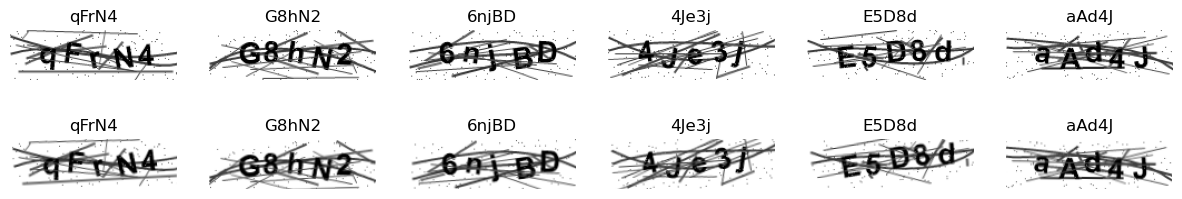

In [4]:
def to_input(x):
    """uint8 (B, H, W) -> float (B, 1, H, W) with ink = 1, paper = 0."""
    return (1 - x.float() / 255).unsqueeze(1)

def batches(split, batch_size, shuffle):
    idx, y = data[split]
    order = torch.randperm(len(idx)) if shuffle else torch.arange(len(idx))
    for k in range(0, len(idx), batch_size):
        j = order[k:k + batch_size]
        yield to_input(X[idx[j].to(DEVICE)]), y[j].to(DEVICE)

def augment(x, max_shift=4, max_rot=4):
    """Random shift (px) and rotation (degrees) per image, whole batch at once on the GPU.
    No flips: a mirrored letter is a different letter."""
    b, _, h, w = x.shape
    rnd = lambda: torch.rand(b, device=x.device) * 2 - 1
    ang = rnd() * max_rot * math.pi / 180
    cos, sin = torch.cos(ang), torch.sin(ang)
    tx, ty = rnd() * max_shift * 2 / w, rnd() * max_shift * 2 / h
    # rotation in normalised coordinates, corrected for the 150x45 aspect ratio
    theta = torch.stack([torch.stack([cos, -sin * h / w, tx], 1),
                         torch.stack([sin * w / h, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

# sanity check: originals (top) vs augmented (bottom)
x, y = next(batches("train", 6, shuffle=True))
fig, ax = plt.subplots(2, 6, figsize=(15, 2.6))
for k, img in enumerate(torch.cat([x, augment(x)]).cpu()):
    ax[k // 6, k % 6].imshow(img[0], cmap="gray_r", vmin=0, vmax=1)
    ax[k // 6, k % 6].set_title(decode_pred(y[k % 6].tolist()))
    ax[k // 6, k % 6].axis("off")
plt.show()

In [5]:
class CaptchaCNN(nn.Module):
    def __init__(self, n_classes, length=LENGTH, widths=(32, 64, 128, 192), dropout=0.3):
        super().__init__()
        layers, c_in = [], 1
        for c in widths:   # each block halves H and W: 45x150 -> 2x9
            layers += [
                nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            c_in = c
        self.features = nn.Sequential(*layers)
        n_cols = W // 2 ** len(widths)   # 9 columns left, kept apart so heads know left from right
        self.shared = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                    nn.Linear(c_in * n_cols, 512), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.heads = nn.ModuleList(nn.Linear(512, n_classes) for _ in range(length))

    def forward(self, x):
        z = self.features(x).mean(dim=2)   # average over height -> (B, C, columns)
        z = self.shared(z)
        return torch.stack([head(z) for head in self.heads], dim=1)   # (B, LENGTH, n_classes)

m = CaptchaCNN(len(ALPHABET))
print(f"{sum(p.numel() for p in m.parameters()) / 1e6:.2f}M parameters")

1.82M parameters


In [6]:
from tqdm.auto import tqdm

@torch.no_grad()
def predict(model, split, batch_size=1024):
    model.eval()
    return torch.cat([model(x).argmax(-1).cpu() for x, _ in batches(split, batch_size, shuffle=False)])

def evaluate(model, split):
    p, y = predict(model, split), data[split][1]
    return {"exact": (p == y).all(1).float().mean().item(), "char": (p == y).float().mean().item()}

def train(cfg, tag=""):
    """Trains with cfg; keeps the epoch with the best val exact-match. Returns (model, best val)."""
    torch.manual_seed(cfg["seed"])
    model = CaptchaCNN(len(ALPHABET), dropout=cfg["dropout"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps_per_epoch = math.ceil(len(data["train"][0]) / cfg["batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], total_steps=cfg["epochs"] * steps_per_epoch)
    best, best_state, stale = -1.0, None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        t, total = time.time(), torch.zeros((), device=DEVICE)
        bar = tqdm(batches("train", cfg["batch"], shuffle=True), total=steps_per_epoch,
                   desc=f"{tag}epoch {epoch}/{cfg['epochs']}", leave=False)
        for step, (x, y) in enumerate(bar, 1):
            if cfg["augment"]:
                x = augment(x)
            loss = F.cross_entropy(model(x).flatten(0, 1), y.flatten(), label_smoothing=cfg["smoothing"])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            total += loss.detach()
            if step % 50 == 0:   # reading the loss forces a GPU sync, so only now and then
                bar.set_postfix(loss=f"{total.item() / step:.3f}")
        val = evaluate(model, "val")
        gold_r = evaluate(model, "gold")
        print(f"{tag}epoch {epoch:>2}/{cfg['epochs']}  loss {total.item() / steps_per_epoch:.3f}  "
              f"val exact {val['exact']:.2%}  char {val['char']:.2%}  "
              f"gold exact {gold_r['exact']:.2%}  {time.time() - t:.0f}s", flush=True)
        
        if val["exact"] > best:
            best, stale = val["exact"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= cfg["patience"]:
                print(f"{tag}stopping early, no val gain for {stale} epochs")
                break
    model.load_state_dict(best_state)
    return model, best

CFG = dict(epochs=25, batch=256, lr=2e-3, weight_decay=1e-4, dropout=0.3,
           smoothing=0.1, augment=True, patience=5, seed=SEED)

/Users/varunmatta/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Short runs, one setting changed at a time. Copy the winner into CFG before cell 8.
# The first run prints how long an epoch takes; 5 runs x 4 epochs in total.
search = {"lr": [1e-3, 2e-3, 4e-3], "dropout": [0.2, 0.5]}
results = []
for name, values in search.items():
    for v in values:
        cfg = {**CFG, name: v, "epochs": 4, "patience": 2}
        _, val_exact = train(cfg, tag=f"[{name}={v}] ")
        results.append((name, v, val_exact))
        print(f"==> {name} = {v:<7} best val exact {val_exact:.2%}\n", flush=True)
print(sorted(results, key=lambda r: -r[2]))

In [7]:
model, best_val = train(CFG)
print(f"best val exact: {best_val:.2%}")

epoch  1/25  loss 3.172  val exact 15.44%  char 70.60%  gold exact 16.45%  88s


epoch  2/25  loss 1.308  val exact 81.83%  char 95.94%  gold exact 90.79%  88s


epoch  3/25  loss 0.968  val exact 82.89%  char 96.20%  gold exact 89.47%  88s


epoch  4/25  loss 0.924  val exact 83.52%  char 96.32%  gold exact 90.13%  93s


epoch  5/25  loss 0.904  val exact 82.43%  char 96.05%  gold exact 86.84%  94s


epoch  6/25  loss 0.895  val exact 82.74%  char 96.14%  gold exact 89.47%  96s


... (15 outputs left out)

epoch 22/25  loss 0.811  val exact 84.87%  char 96.64%  gold exact 87.50%  88s


epoch 23/25  loss 0.809  val exact 85.02%  char 96.66%  gold exact 86.84%  87s


epoch 24/25  loss 0.807  val exact 84.95%  char 96.64%  gold exact 86.84%  88s


epoch 25/25  loss 0.807  val exact 84.91%  char 96.64%  gold exact 86.18%  88s
best val exact: 85.02%


val   ( 12195 images)  exact 85.02%  char 96.66%
test  ( 24387 images)  exact 84.74%  char 96.49%
gold  (   152 images)  exact 86.84%  char 97.24%
Vision raw read on gold, for comparison: 75.00% (before lookalike fixes)
per-position accuracy on gold: ['96.1%', '97.4%', '97.4%', '97.4%', '98.0%']
most common confusions on gold (true -> predicted): [(('9', 'g'), 6), (('q', 'a'), 3), (('y', 'Y'), 2), (('q', '9'), 2), (('g', '9'), 2), (('j', 'i'), 1), (('8', 'g'), 1), (('i', 'j'), 1), (('D', 'B'), 1), (('Y', 'y'), 1)]


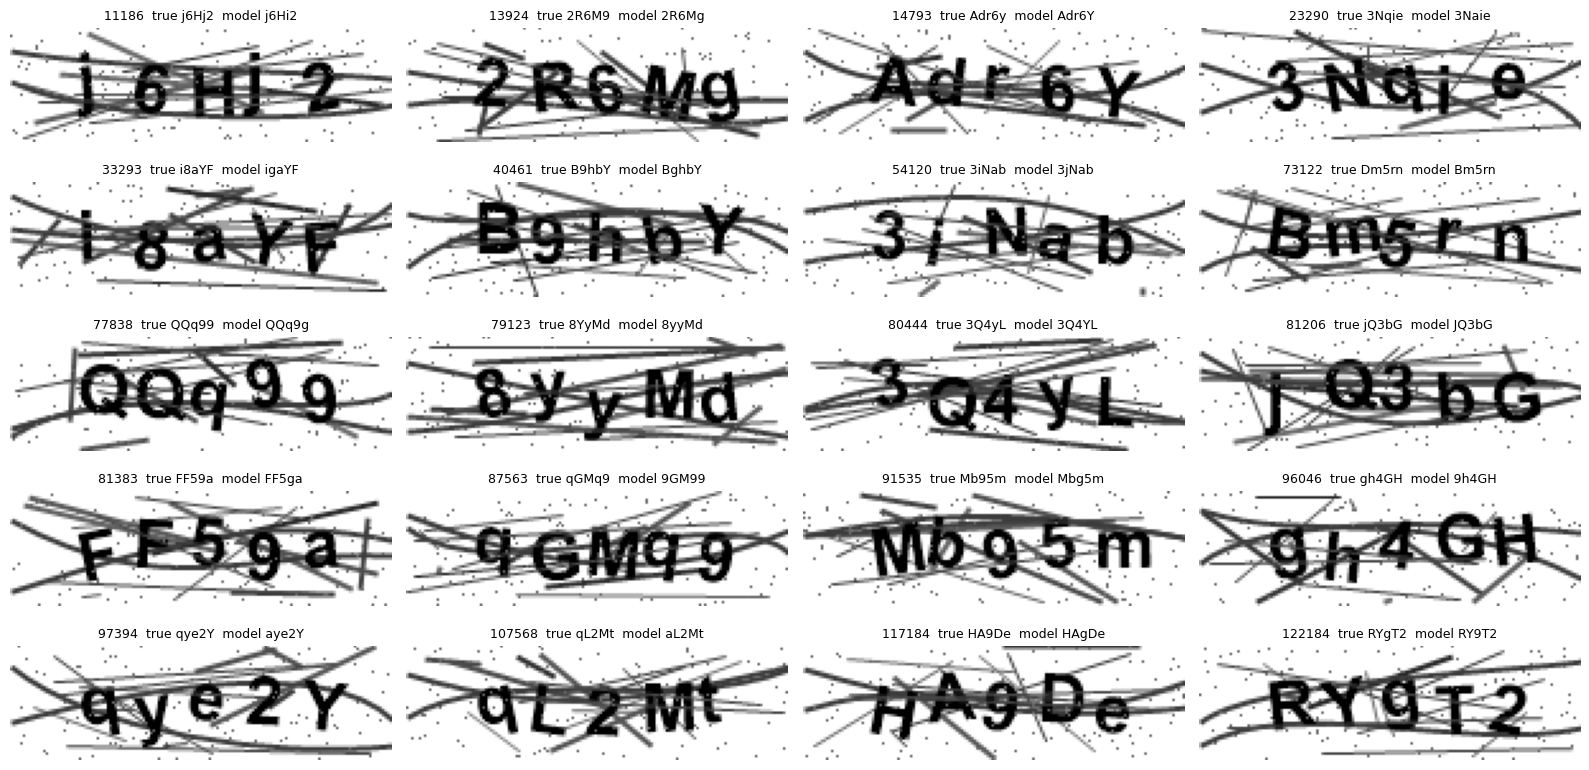

In [15]:
# test = held-out Vision labels (agreement with Vision); gold = hand-checked (agreement with truth)
for split in ("val", "test", "gold"):
    r = evaluate(model, split)
    print(f"{split:<5} ({len(data[split][0]):>6} images)  exact {r['exact']:.2%}  char {r['char']:.2%}")

vision_gold = sum(r["raw"] == r["label"] for r in gold) / len(gold)
print(f"Vision raw read on gold, for comparison: {vision_gold:.2%} (before lookalike fixes)")

p_gold, y_gold = predict(model, "gold"), data["gold"][1]
print("per-position accuracy on gold:", [f"{a:.1%}" for a in (p_gold == y_gold).float().mean(0).tolist()])
mix = Counter((ALPHABET[t], ALPHABET[q]) for pp, yy in zip(p_gold, y_gold)
              for t, q in zip(yy.tolist(), pp.tolist()) if t != q)
print("most common confusions on gold (true -> predicted):", mix.most_common(10))

wrong = [k for k in range(len(gold)) if not torch.equal(p_gold[k], y_gold[k])]
cols = 4
rows_n = max(1, math.ceil(len(wrong) / cols))
fig, ax = plt.subplots(rows_n, cols, figsize=(16, 1.6 * rows_n), squeeze=False)
for a in ax.flat:
    a.axis("off")
for a, k in zip(ax.flat, wrong):
    a.imshow(imgs[row_of[gold[k]["id"]]], cmap="gray")
    a.set_title(f"{gold[k]['id']}  true {gold[k]['label']}  model {decode_pred(p_gold[k].tolist())}", fontsize=9)
plt.tight_layout()
plt.show()

In [12]:
torch.save({
    "state_dict": model.state_dict(),
    "alphabet": ALPHABET,
    "length": LENGTH,
    "image_size": (H, W),
    "widths": (32, 64, 128, 192),
    "config": CFG,
    "input": "grayscale HxW, x = 1 - pixel/255 (ink = 1), shape (B, 1, H, W)",
    "scores": {s: evaluate(model, s) for s in ("val", "test", "gold")},
}, MODEL_PATH)

def load_model(path=MODEL_PATH):
    ckpt = torch.load(path, map_location=DEVICE)
    m = CaptchaCNN(len(ckpt["alphabet"]), ckpt["length"], ckpt["widths"], ckpt["config"]["dropout"]).to(DEVICE)
    m.load_state_dict(ckpt["state_dict"])
    return m.eval(), ckpt

reloaded, ckpt = load_model()
assert torch.equal(predict(reloaded, "gold"), predict(model, "gold")), "reloaded model predicts differently"
print(f"saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB), reload OK:", ckpt["scores"])

saved captcha_cnn.pt (7.3 MB), reload OK: {'val': {'exact': 0.8501845002174377, 'char': 0.9665764570236206}, 'test': {'exact': 0.8474187254905701, 'char': 0.964850127696991}, 'gold': {'exact': 0.8684210777282715, 'char': 0.9723684191703796}}


In [13]:
@torch.no_grad()
def read_captcha(path, model=reloaded, alphabet=ckpt["alphabet"]):
    x = torch.from_numpy(np.array(Image.open(path).convert("L")))[None].to(DEVICE)
    probs = model(to_input(x)).softmax(-1)[0]           # (LENGTH, n_classes)
    conf, idx = probs.max(-1)
    return "".join(alphabet[i] for i in idx.tolist()), conf.min().item()   # weakest character's confidence

for i in ("57710", "94667", "87563"):
    print(i, read_captcha(os.path.join(IMAGES, f"{i}.png")))

57710 ('d5JMd', 0.8606470227241516)
94667 ('4RmFj', 0.7317550182342529)
87563 ('9GM99', 0.7369014024734497)


In [14]:
@torch.no_grad()
def model_reads(ids, batch_size=1024):
    reads, confs = [], []
    for k in range(0, len(ids), batch_size):
        x = X[torch.tensor([row_of[i] for i in ids[k:k + batch_size]]).to(DEVICE)]
        probs = model(to_input(x)).softmax(-1)
        conf, idx = probs.max(-1)
        reads += ["".join(ALPHABET[i] for i in p) for p in idx.cpu().tolist()]
        confs += conf.min(-1).values.cpu().tolist()
    return reads, confs

model.eval()
pool = list(auto)   # Vision-labeled only; gold stays untouched as the final test
reads, confs = model_reads([r["id"] for r in pool])
queue = sorted(((r["id"], r["label"], m, c) for r, m, c in zip(pool, reads, confs) if m != r["label"]),
               key=lambda t: -t[3])
with open("review_queue.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["id", "vision_label", "model_read", "model_confidence"])
    w.writerows(queue)
print(f"{len(queue)} of {len(pool)} Vision labels disagree with the model -> review_queue.csv")
print(queue[:10])

15411 of 121937 Vision labels disagree with the model -> review_queue.csv
[('29980', 'G5raj', 'G5rai', 0.9320665001869202), ('93568', 'eRrN4', 'eRtN4', 0.9289371371269226), ('21433', 'deaMg', 'deaM8', 0.9282099008560181), ('67272', 'NigFm', 'MgFm2', 0.9281043410301208), ('74934', 'g5yR8', '85yR8', 0.9276484251022339), ('82989', 'e3yhb', 'e3yhD', 0.9262313842773438), ('26583', '2yfDm', '2ytDm', 0.9253728985786438), ('30693', 'J3F8T', 'J3F8r', 0.9251114130020142), ('118269', 'eybY4', 'egbY4', 0.9235190749168396), ('87861', 'e3mgF', 'e3mnF', 0.9234130382537842)]


---

## Cell A: review the model's reads (Enter = right, type the truth if wrong, s = skip, q = quit)

uncertain: 2000 candidates, reviewing 50; 600 reviewed so far


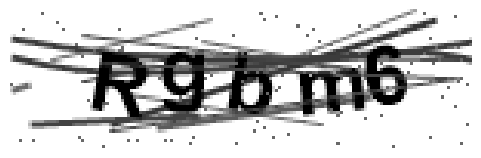

[1/50] 84271  model: Rgbm6  (Vision: R9bm6, conf 0.44)  Enter=right / type truth / s=skip / q=quit:  


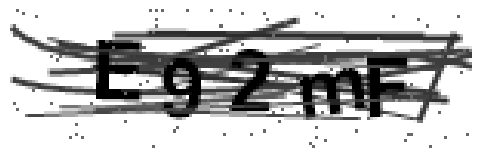

[2/50] 3510  model: E92mF  (Vision: Eg2mF, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  


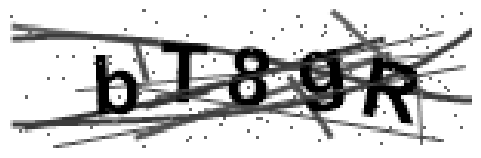

[3/50] 114913  model: bT89R  (Vision: bT89R, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  bt8gR


  model wrong: t -> T @1, g -> 9 @3


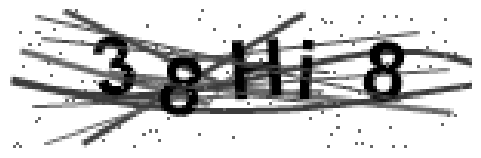

[4/50] 54796  model: 38Hi8  (Vision: 3gHi8, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  


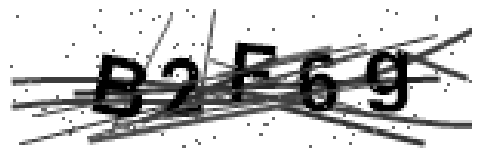

[5/50] 102627  model: B2F6g  (Vision: B2F69, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


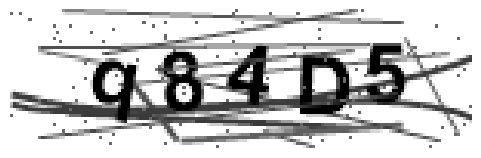

[6/50] 101676  model: 984D5  (Vision: 984D5, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  q84D5


  model wrong: q -> 9 @0


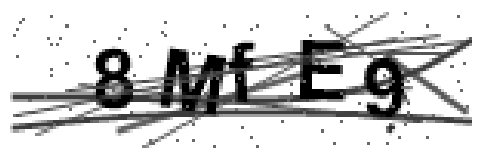

[7/50] 98303  model: 8MfE9  (Vision: 8MfEg, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


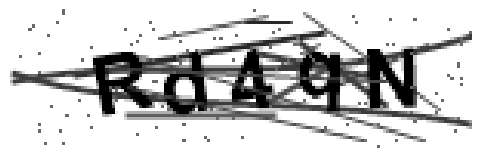

[8/50] 21614  model: Rd4qN  (Vision: Rd49N, conf 0.45)  Enter=right / type truth / s=skip / q=quit:  


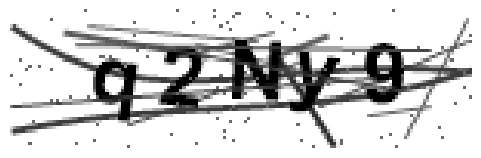

[9/50] 115679  model: q2Ny9  (Vision: q2Ny9, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  


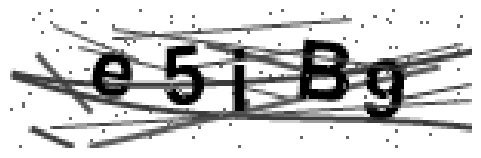

[10/50] 50942  model: e5iBg  (Vision: e5iBg, conf 0.47)  Enter=right / type truth / s=skip / q=quit:  


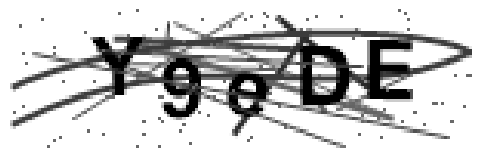

[11/50] 87595  model: Y9eDE  (Vision: YgeDE, conf 0.45)  Enter=right / type truth / s=skip / q=quit:  


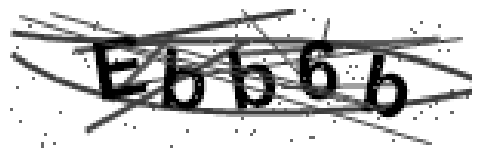

[12/50] 50410  model: Ebb6b  (Vision: 99993, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


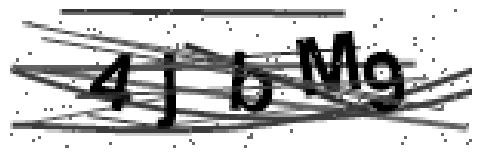

[13/50] 40416  model: 4jbMg  (Vision: 4jbMg, conf 0.47)  Enter=right / type truth / s=skip / q=quit:  


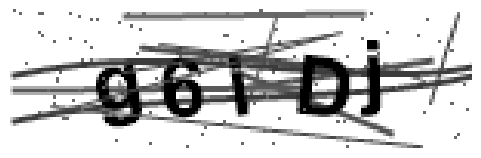

[14/50] 121801  model: g6iDi  (Vision: 96fDi, conf 0.44)  Enter=right / type truth / s=skip / q=quit:  


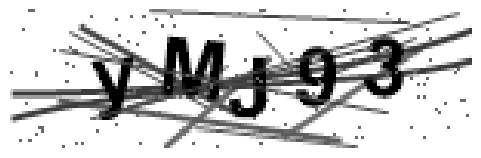

[15/50] 117870  model: yMj93  (Vision: yMj93, conf 0.43)  Enter=right / type truth / s=skip / q=quit:  yMJ93


  model wrong: J -> j @2


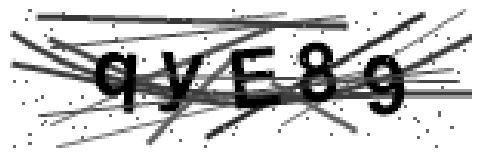

[16/50] 90972  model: qyE8g  (Vision: qyE8g, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  qyE89


  model wrong: 9 -> g @4


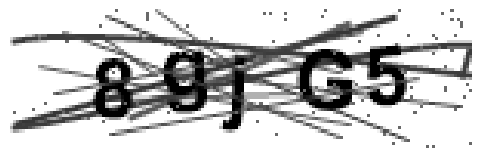

[17/50] 89171  model: 8gjG5  (Vision: 89jG5, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  


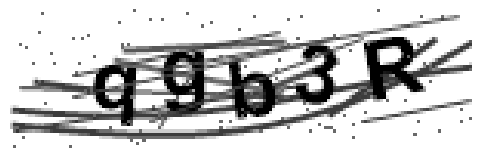

[18/50] 5451  model: q9b3R  (Vision: 99b3R, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  qgb3R


  model wrong: g -> 9 @1


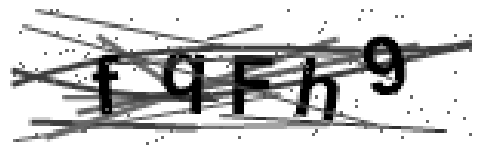

[19/50] 14238  model: fqFh9  (Vision: F9Fh9, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


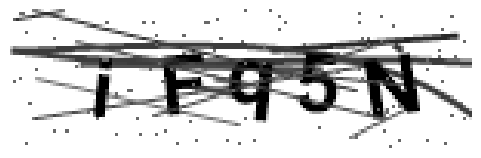

[20/50] 109968  model: iF95N  (Vision: iF95N, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


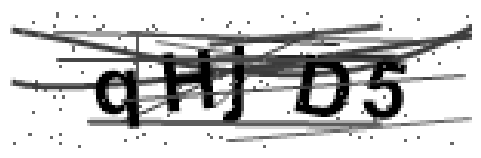

[21/50] 72992  model: qHjD5  (Vision: qHjD5, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  


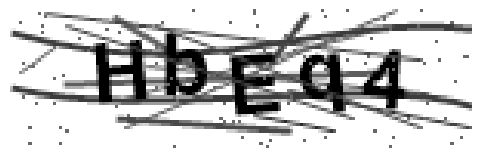

[22/50] 53296  model: HbE94  (Vision: HDE94, conf 0.47)  Enter=right / type truth / s=skip / q=quit:  HbEq4


  model wrong: q -> 9 @3


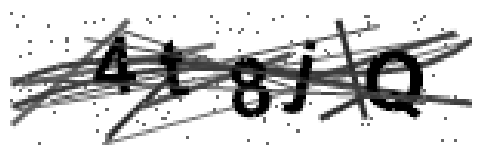

[23/50] 33444  model: 4t8JQ  (Vision: 4fgjQ, conf 0.45)  Enter=right / type truth / s=skip / q=quit:  4t8jQ


  model wrong: j -> J @3


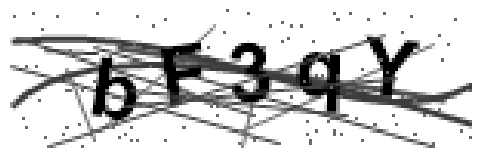

[24/50] 25577  model: 6F3qY  (Vision: 6F3QY, conf 0.52)  Enter=right / type truth / s=skip / q=quit:  bF3qY


  model wrong: b -> 6 @0


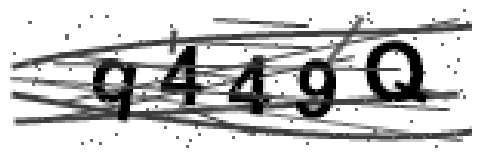

[25/50] 72244  model: q449Q  (Vision: 9449Q, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


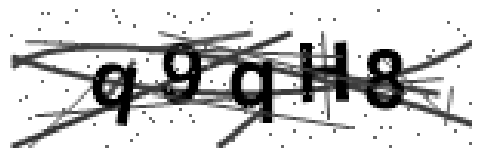

[26/50] 32397  model: q9qH8  (Vision: 99qH8, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  


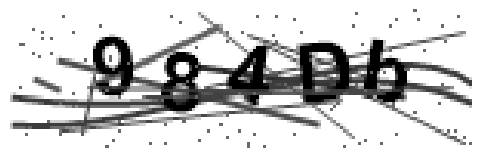

[27/50] 103435  model: 984Db  (Vision: 984D6, conf 0.52)  Enter=right / type truth / s=skip / q=quit:  


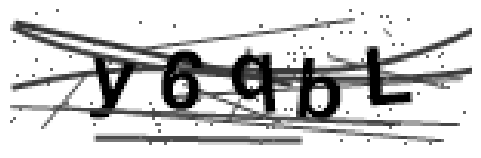

[28/50] 82684  model: y69bL  (Vision: y69bL, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  y6qbL


  model wrong: q -> 9 @2


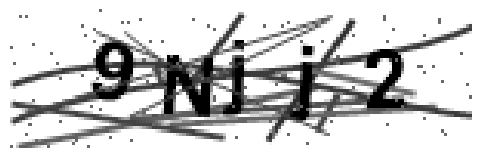

[29/50] 95451  model: 9Nij2  (Vision: 9Nii2, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  9Njj2


  model wrong: j -> i @2


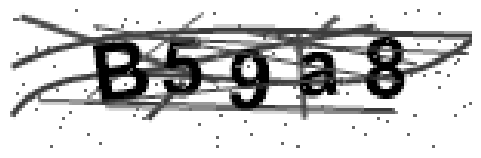

[30/50] 44067  model: B59a8  (Vision: B59a8, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


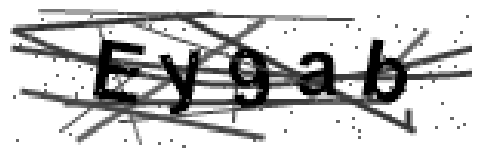

[31/50] 52858  model: Eygab  (Vision: Eygab, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  Ey9ab


  model wrong: 9 -> g @2


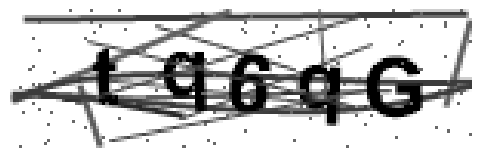

[32/50] 78123  model: t96qG  (Vision: t96qG, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  


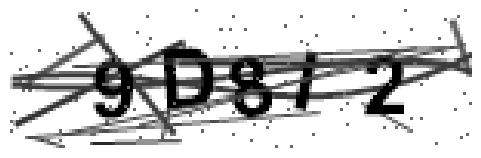

[33/50] 29731  model: 9D8i2  (Vision: 9D8j2, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  


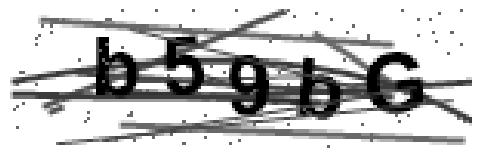

[34/50] 121954  model: b59bG  (Vision: b59bG, conf 0.54)  Enter=right / type truth / s=skip / q=quit:  


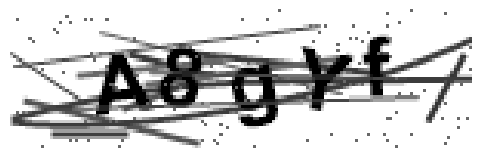

[35/50] 111356  model: A8gYf  (Vision: A8gYf, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


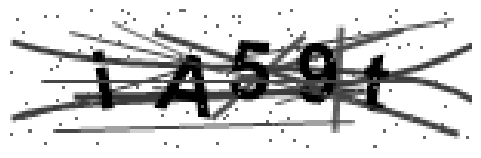

[36/50] 35377  model: iA59t  (Vision: fA59t, conf 0.46)  Enter=right / type truth / s=skip / q=quit:  


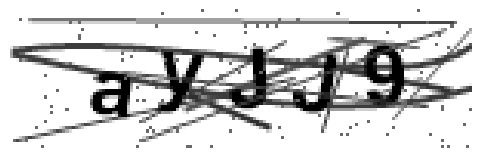

[37/50] 64829  model: aYJJ9  (Vision: aYJJ9, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  ayJJ9


  model wrong: y -> Y @1


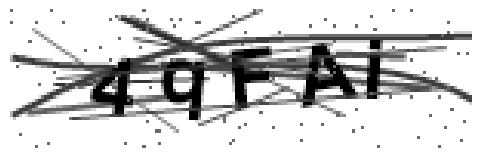

[38/50] 62419  model: 49FAi  (Vision: 49FAi, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  4qFAi


  model wrong: q -> 9 @1


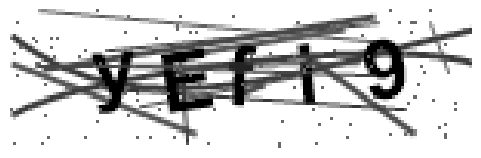

[39/50] 101040  model: yEfi9  (Vision: YEfi9, conf 0.52)  Enter=right / type truth / s=skip / q=quit:  yEfi9


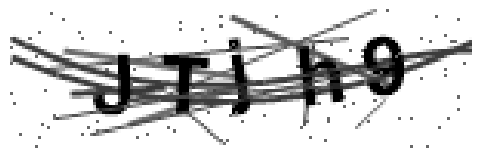

[40/50] 115647  model: JTjh9  (Vision: JTih9, conf 0.43)  Enter=right / type truth / s=skip / q=quit:  


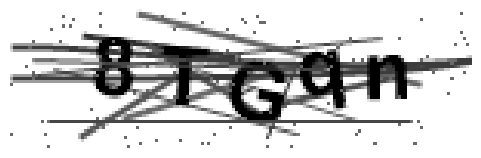

[41/50] 1735  model: 8TGqn  (Vision: 8TGan, conf 0.47)  Enter=right / type truth / s=skip / q=quit:  


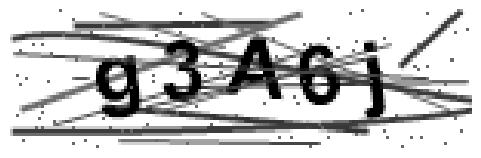

[42/50] 34237  model: g3A6j  (Vision: g3A6j, conf 0.43)  Enter=right / type truth / s=skip / q=quit:  


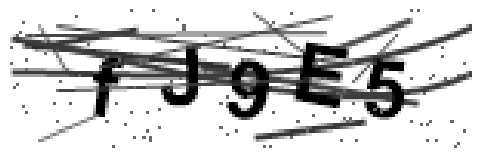

[43/50] 103682  model: fJ9E5  (Vision: fJgE5, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


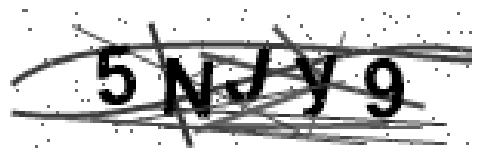

[44/50] 1037  model: 5NJY9  (Vision: 5NJY9, conf 0.48)  Enter=right / type truth / s=skip / q=quit:  5NJy9


  model wrong: y -> Y @3


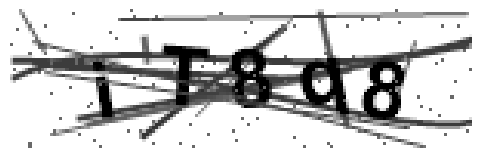

[45/50] 102060  model: fT8q8  (Vision: fT898, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  iT8q8


  model wrong: i -> f @0


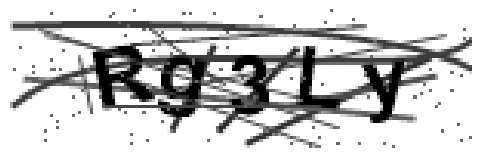

[46/50] 29690  model: Rg3Ly  (Vision: Rg3LY, conf 0.50)  Enter=right / type truth / s=skip / q=quit:  


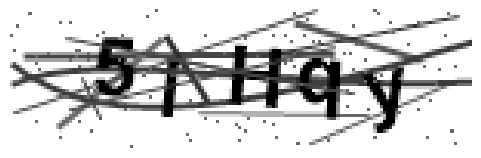

[47/50] 8939  model: 5iHqy  (Vision: 5jHay, conf 0.51)  Enter=right / type truth / s=skip / q=quit:  


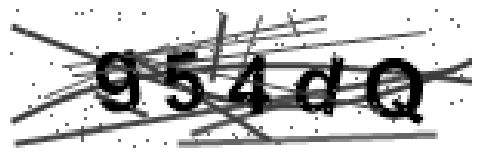

[48/50] 78453  model: 954dQ  (Vision: 954dQ, conf 0.52)  Enter=right / type truth / s=skip / q=quit:  g54dQ


  model wrong: g -> 9 @0


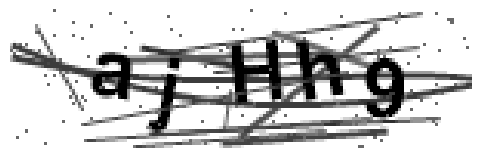

[49/50] 69686  model: ajHhg  (Vision: ajHh9, conf 0.53)  Enter=right / type truth / s=skip / q=quit:  ajHh9


  model wrong: 9 -> g @4


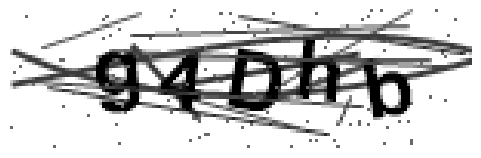

[50/50] 23686  model: 94Dhb  (Vision: 94Dhb, conf 0.49)  Enter=right / type truth / s=skip / q=quit:  



650 reviewed in total: model right 461, wrong 189
model confusions (true -> model): [(('q', '9'), 54), (('9', 'g'), 38), (('g', '9'), 17), (('8', 'g'), 15), (('q', 'a'), 15), (('y', 'Y'), 12), (('b', '6'), 10), (('i', 'j'), 7), (('Y', 'y'), 6), (('j', 'i'), 6)]


In [37]:
%run -i review_model.py

## Cell B: fine-tune on your reviews (run after cell A)

In [38]:
%run -i finetune_model.py

650 reviewed captchas, model was wrong on 189
each review repeated 5x per epoch
epoch 1/2  reviewed exact 89.08%  gold exact 94.08%
epoch 2/2  reviewed exact 92.46%  gold exact 93.42%

                  before  ->  after
reviewed  exact  37.38% ->  92.46%   char  86.34% ->  98.46%
gold      exact  86.84% ->  93.42%   char  97.24% ->  98.68%
test      exact  84.74% ->  82.26%   char  96.49% ->  95.92%
saved captcha_cnn_ft.pt


In [40]:
base_model, _ = load_model(MODEL_PATH)
p_base, p_ft, y = predict(base_model, "gold"), predict(ft_model, "gold"), data["gold"][1]
for k, r in enumerate(gold):
    b, f = torch.equal(p_base[k], y[k]), torch.equal(p_ft[k], y[k])
    if b != f:
        print(f"{'FIXED ' if f else 'BROKEN'} {r['id']}  true {r['label']}  "
              f"baseline {decode_pred(p_base[k].tolist())}  fine-tuned {decode_pred(p_ft[k].tolist())}")

BROKEN 13887  true id3gM  baseline id3gM  fine-tuned id39M
FIXED  23290  true 3Nqie  baseline 3Naie  fine-tuned 3Nqie
BROKEN 27695  true D59fD  baseline D59fD  fine-tuned D5gfD
FIXED  33293  true i8aYF  baseline igaYF  fine-tuned i8aYF
FIXED  54120  true 3iNab  baseline 3jNab  fine-tuned 3iNab
FIXED  77838  true QQq99  baseline QQq9g  fine-tuned QQq99
FIXED  81206  true jQ3bG  baseline JQ3bG  fine-tuned jQ3bG
FIXED  81383  true FF59a  baseline FF5ga  fine-tuned FF59a
FIXED  87563  true qGMq9  baseline 9GM99  fine-tuned qGMq9
FIXED  91535  true Mb95m  baseline Mbg5m  fine-tuned Mb95m
FIXED  96046  true gh4GH  baseline 9h4GH  fine-tuned gh4GH
FIXED  97394  true qye2Y  baseline aye2Y  fine-tuned qye2Y
FIXED  107568  true qL2Mt  baseline aL2Mt  fine-tuned qL2Mt
BROKEN 113979  true e6NGN  baseline e6NGN  fine-tuned e6N6N
FIXED  117184  true HA9De  baseline HAgDe  fine-tuned HA9De
FIXED  122184  true RYgT2  baseline RY9T2  fine-tuned RYgT2
